# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:

**1. Список віршів чи один суцільний рядок (демо 2.1)**

Я зрозумів так: тренер BPE вчиться, які шматочки слів трапляються разом найчастіше, і для цього читає текст порціями. Тому в демо йому дають список віршів: він бере вірш за віршем.

Якщо дати інакше, є два випадки:

- **Один гігантський рядок у списку, `[corpus_text]`.** Усе спрацює, і словник вийде майже таким самим, бо слова все одно ріжуться по пробілах. Але 60 млн символів як один шматок це більше пам'яті й повільніше, бо роботу не можна розділити між ядрами.
- **Просто рядок `corpus_text` без списку.** Це гірше, і помилки не буде. Python, коли проходить по рядку, віддає по одному символу. Тренер вирішить, що кожна «порція» це одна літера, і склеювати йому буде нічого. Замість 16000 шматочків-слів вийде невеликий набір окремих літер, і кожне слово розпадеться на букви.

Нюанс: ніяка помилка не з'являється, тож зламану токенізацію легко не помітити. Її видно лише по тому, що словник став крихітним, а послідовності величезними.

**2. З яких етапів складається токенізація**

Уявляю це як конвеєр з чотирьох станцій:

1. **Normalization.** Прибираємо сміття в тексті: зайві пробіли, інколи робимо літери малими. У демо цей етап не налаштовували, тож текст іде як є.
2. **Pre-tokenization.** Грубо ріжемо текст на «слова». Токен не може вийти за межі такого слова. У демо це `ByteLevel`, який ще й чіпляє пробіл до наступного слова. Тому в токенах видно ` та`, ` стогне` із пробілом на початку.
3. **Model.** Головний алгоритм (BPE, WordPiece або Unigram). Він розрізає кожне слово на шматочки зі словника. У демо це BPE. Наприклад, «Реве та стогне, і здригається Дніпро» став 10 токенами: `Р`, `ев`, `е`, ` та`, ` стогне`, `,`, ` і`, ` здриг`, `ається`, ` Дніпро`.
4. **Post-processing.** Додаємо службові токени (на початок чи кінець). У демо цього етапу немає: `<eos>` ми дописуємо вручну в 2.2. Ще є декодер (`ByteLevel`), який вміє зібрати токени назад у текст.

Нюанс: у демо реально налаштовані лише pre-tokenizer, model і decoder. Normalization і post-processing просто не використовуються.

**3. Що таке `<unk>` і `<eos>`**

- `<unk>` означає «невідомо». Це заглушка для шматочка, якого немає у словнику. Вона є в словнику під номером 0. У нас її частка 0.0%.
- `<eos>` означає «кінець тексту». Вона має номер 1. Ми самі дописуємо її в кінець кожного вірша (демо 2.2), щоб модель бачила, де один вірш закінчився, а інший почався.

Нюанс про `<unk>`: 0% у нас тому, що `ByteLevel` розбиває текст на байти, а будь-який символ складається з байтів. Але гарантією це є лише тоді, коли в словнику є всі 256 байтів. У демо `initial_alphabet` не заданий, тож алфавіт береться з корпусу. Просто на 60 млн символів трапилися всі потрібні байти, тому на практиці `<unk>` не з'являється.

**4. Менший `VOCAB_SIZE`: 16000 → 5000**

Код (повна клітинка є в демо одразу після 2.1). Я навчаю ще один токенізатор на 5000 і рахую статистику на однакових 3000 віршах:

```python
random.seed(42)
poems_all = poems_df["context_poem"].dropna().tolist()
sample_poems = random.sample(poems_all, 3000)   # однакова вибірка для обох токенізаторів

def train_bpe(vocab_size):
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS)
    tok.train_from_iterator(poems_all, trainer=trainer)
    return tok

def tokenizer_stats(tok):
    encs = tok.encode_batch(sample_poems)
    unk_id = tok.token_to_id("<unk>")
    total = sum(len(e.ids) for e in encs)
    unk = sum(e.ids.count(unk_id) for e in encs)
    return total / len(encs), unk / total

tok_5000 = train_bpe(5000)   # 16000 беремо готовий bpe_tokenizer з демо
```

**Результат:**

| `VOCAB_SIZE` | токенів на вірш | частка `<unk>` |
|---|---|---|
| 16000 | 1001.9 | 0.0000% |
| 5000 | 1176.7 | 0.0000% |

Той самий рядок «Реве та стогне, і здригається Дніпро» дає 10 токенів при 16000 і 12 токенів при 5000: `стогне` розпалося на `стог` + `не`, а `Дніпро` на `Дніп` + `ро`.

**Пояснення.** Словник це набір цеглинок. Коли цеглинок багато (16000), є великі готові шматки, наприклад цілі слова, і вірш складається з меншої кількості токенів. Коли їх мало (5000), слова доводиться складати з дрібніших шматочків, тож токенів стає більше. У нас на вірш їх на 17% більше.

`<unk>` не зростає, бо будь-яке слово можна скласти з найдрібніших цеглинок (байтів). Нічого не лишається «невідомим», воно лише розпадається на більше частин.

Для моделі це важливо, бо вона завжди бачить рівно `CONTEXT_LEN = 64` токени. Якщо токени дрібніші, ті самі 64 токени вміщають приблизно на 15% менше тексту (1 − 1001.9/1176.7). До того ж на той самий корпус потрібно більше токенів і більше кроків навчання, щоб один раз його «прочитати».

**5. Навіщо `<eos>` між віршами (демо 2.2)**

Я уявляю, що без `<eos>` усі вірші зливаються в одну довгу кашу. Останнє слово одного вірша опиняється впритул до першого слова зовсім іншого, і модель вчиться, що це нормальне продовження. Вона не знає, де вірш закінчується, і не вміє завершувати текст. З `<eos>` межа чітка: тут кінець, далі нова історія.

Нюанс: у демо функція `generate` не зупиняється на `<eos>` сама, вона просто видає `max_new_tokens` токенів. Тобто вміння «зупинитись» у нашому демо нікуди не використовується. Але навчальний сигнал про межу вірша модель усе одно отримує.

**6. Що лежить у `train_data` і `val_data` (демо 2.3)**

Це два довгі одновимірні списки цілих чисел (тензори типу `int64`, тобто `long`). Кожне число це номер токена в словнику `itos` (від 0 до 15999). Увесь текст перетворений на ці номери, наприклад «Реве та стогне» стає кількома номерами: по одному на кожен токен (`Р`, `ев`, `е`, ` та`, ` стогне`).

`train_data` це перші 90% корпусу (16 579 771 токен), `val_data` це останні 10% (1 842 197 токенів). Спліт послідовний, а не випадковий, бо модель вчиться «що йде далі», тож порядок токенів не можна перемішувати.

Нюанс про `int64`: `nn.Embedding` та `cross_entropy` очікують саме цілі числа типу `long`. Це не ймовірності й не вектори. Це лише номери, а вектори з них вже робить шар `Embedding`.

**7. `assert` для батча (демо 3.2)**

Ідея: модель вчиться вгадувати наступний токен для кожної позиції. Тому `y` має бути тим самим текстом, що й `x`, але зсунутим на один токен вперед. Тест перевіряє: правильні розміри, правильний тип, що номери не виходять за межі словника, і що `y` справді зсунутий `x`.

```python
xb, yb = get_batch("train")
assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN)
assert xb.dtype == torch.long and yb.dtype == torch.long
assert xb.min() >= 0 and xb.max() < len(itos), "id поза межами словника"
# таргет = вхід, зсунутий на 1 токен вперед
assert torch.equal(xb[:, 1:], yb[:, :-1]), "y має бути x, зсунутим на 1 токен"
print("get_batch: усі перевірки пройдено")
```

**Результат:** `get_batch: усі перевірки пройдено`.

**8. Чому маска нижньотрикутна (демо 3.3)**

Уявляю таблицю: рядок це «хто дивиться», стовпчик це «на кого дивиться». Токен на позиції 5 має право дивитись на 1, 2, 3, 4, 5 (минуле і себе), але не на 6, 7, 8 (майбутнє). У таблиці це саме нижній трикутник. Верхній трикутник дозволив би дивитись у майбутнє і забороняв би минуле, тобто навпаки.

У коді заборонені місця заповнюються `-inf` перед `softmax`, і вага там стає рівно 0:

```python
scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
```

Без маски під час навчання модель побачила б правильну відповідь просто у вхідному тексті і «списувала» б її. Loss швидко впав би, але нічого корисного вона б не вивчила. А при генерації майбутніх слів ще не існує, і така модель видавала б сміття.

**9. Коли збігаються найкращий і останній чекпоінти (демо 3.10)**

Я зрозумів так: `val_loss` це оцінка на тексті, якого модель не бачила. Якщо він падає до самого кінця навчання, найкращий чекпоінт це останній, і вони збігаються. Якщо він перестав падати і почав рости, то модель почала «зубрити» навчальний текст (перенавчання), і найкращий чекпоінт був раніше.

У мене перший випадок. Найкращий чекпоінт це iter 7999 з `val_loss = 5.665`, тобто останній. Крива майже весь час іде вниз. Є лише дрібні «горбики» (наприклад, на 5000-й ітерації 5.949 після 5.930 на 4750-й), але це шум: `val_loss` рахується лише по 50 батчах. Різниця train/val мала (5.576 проти 5.665), тож перенавчання немає.

Нюанс: це означає, що модель ще недонавчена. Якби тренували довше, loss, ймовірно, падав би далі.

**10. `EVAL_INTERVAL` у 5 разів менший: 250 → 50 (демо 3.8)**

Що я змінив (повний код у клітинці демо після 3.10): `EVAL_INTERVAL_E50 = 50`, нова модель `model_e50`, окремий `log_dir` (`mini_gpt_eval50`), щоб не перезаписати попередній результат.

```python
EVAL_INTERVAL_E50 = 50
model_e50 = MiniGPT(vocab_size=len(itos), embed_dim=EMBED_DIM, n_heads=N_HEADS,
                    n_layers=N_LAYERS, context_len=CONTEXT_LEN, dropout=DROPOUT).to(device)
writer_e50 = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "mini_gpt_eval50"))
...
    if it % EVAL_INTERVAL_E50 == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss_e50()      # 50 батчів train + 50 батчів val
        writer_e50.add_scalar("Loss/val", losses["val"], it)
```

**Результат:**

| | `EVAL_INTERVAL=250` | `EVAL_INTERVAL=50` |
|---|---|---|
| час | 6.5 хв | 9.8 хв |
| точок на кривій | 33 | 161 |
| найкращий `val_loss` | 5.665 | 5.651 |

**Пояснення.** Кожна перевірка це 100 додаткових батчів (50 на train і 50 на val). При інтервалі 50 вона трапляється аж у 5 разів частіше, тому +3.3 хв, тобто приблизно +50% часу. А модель краще не стала: `val_loss` майже однаковий, різниця 0.014 це шум.

Крива не стала помітно інформативнішою. Вона лишилась тією самою за формою, просто з більшою кількістю точок. Кожна точка і так приблизна (50 батчів), тому дрібні зигзаги це шум, а не нова інформація.

Робити інтервал ще меншим сенсу немає: перевірки забирали б більше часу, ніж саме навчання. Наприклад, при інтервалі 10 на кожні 10 кроків навчання припадало б 100 батчів оцінки.

**11. Що робить `temperature` (демо 4.2)**

Модель для кожного токена дає число-оцінку (логіт). Перед `softmax` `temperature` ділить усі логіти на одне число T:

$$p_i = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

- **T менше 1** (наприклад 0.2): різниці між логітами збільшуються, лідер «перемагає» ще більше. Текст передбачуваний і одноманітний.
- **T більше 1** (наприклад 1.4): різниці стискаються, шанси вирівнюються. Модель береться за дивні слова.

Приклад із логітами [2, 1, 0]: при T=1 ймовірності ≈ [0.67, 0.24, 0.09]; при T=0.5 ≈ [0.87, 0.12, 0.02] (лідер домінує); при T=2 ≈ [0.51, 0.31, 0.19] (майже порівну).

Чому при дуже високій температурі текст майже випадковий: при T → ∞ усі `z/T` прямують до 0, а `softmax` від майже однакових чисел дає майже рівномірний розподіл. Для T=100 той самий приклад дає ≈ [0.34, 0.33, 0.33]. Тоді модель витягує токен майже навмання серед усіх 16000+ варіантів, і виходить абракадабра.

Приклад із демо: при `temperature=1.4` з'явилися дивні слова на кшталт «вихлипівлення» та «драконівський відібір», а при 0.2 текст був спокійний і передбачуваний.

Нюанс: у демо одночасно змінюються і `temperature`, і `top_p` (0.2/0.1, 0.8/0.6, 1.4/0.8), тому різницю в тексті створює не тільки температура. Це видно з того, що при (0.2, 0.1) і (0.8, 0.6) речення майже однакові.

**12. За що відповідає `top_p`**

Це фільтр «розумних» слів. Модель сортує токени від найімовірнішого до найменш імовірного і бере їх по черзі, доки сума ймовірностей не досягне `p`. Решту викидає, а серед відібраних перераховує ймовірності і вибирає.

Приклад: ймовірності [0.6, 0.25, 0.1, 0.05].
- `top_p = 0.8`: беремо 0.6 + 0.25 = 0.85 ≥ 0.8, лишається 2 токени.
- `top_p = 0.1`: уже перший токен (0.6) перекриває поріг, лишається 1 токен, тобто текст майже завжди однаковий.

Нюанс: `top_p` адаптивний. Коли модель впевнена, лишається 1–2 токени, а коли вагається, лишається багато. Це відрізняє його від `top_k`, який завжди бере фіксовану кількість. У моєму mini-GPT (демо 3.10) використано `top_k=40`, а у Qwen3 (4.2) використано `top_p`.

**13. `enable_thinking=True` (демо 4.2)**

Що я змінив: у новій клітинці (стару залишив, щоб було видно різницю) поставив `enable_thinking=True` і підняв `max_new_tokens` з 300 до 1024:

```python
text = hf_tokenizer.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True, enable_thinking=True
)
...
outputs = hf_model.generate(**inputs, max_new_tokens=1024, do_sample=True,
                            temperature=0.8, top_p=0.6)
```

**Результат:** модель витратила всі 1024 токени на міркування (`<think>…</think>`) і не дійшла до відповіді: закритого тега `</think>` немає, готового продовження речення теж немає. Міркування модель писала англійською, хоча промпт українською. Вона ще й помилилась: сплутала «Житомирської політехніки» з Харківською та Хмельницькою («Kharkiv… Khmelnytskyi») і довго сумнівалась, чи це не помилка в тексті. Без міркування (`enable_thinking=False`, 4.2) на той самий промпт модель одразу видала готову відповідь.

**Пояснення.** З `enable_thinking=True` модель спочатку «думає вголос» у блоці `<think>`, а вже потім відповідає. Це може покращити складні відповіді (логіка, математика, код), але для простого завдання «продовж речення» воно лише з'їдає токени й час. Тому ліміт треба піднімати: при ліміті 300 токенів модель вичерпала б його ще під час міркування. Нюанс: навіть 1024 токенів у моєму запуску не вистачило, тож відповіді немає взагалі. Іншими словами, режим міркування дорожчий за часом і за токенами, і він не гарантує кращого результату.

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

 Для роботи обрано датасет [`slava-medvedev/zelensky-speeches`](https://huggingface.co/datasets/slava-medvedev/zelensky-speeches): виступи Президента України з офіційного сайту president.gov.ua (3698 текстів, колонка `full_text`). Жанр: політична публічна мова (звернення, промови). Датасет двомовний, тому з нього відфільтровано лише україномовні тексти (частка кирилиці понад 70% літер). Дублікати та порожні тексти видалено.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

assert "google.colab" in sys.modules, "Ця лаба має виконуватися в Google Colab"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3"
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)

Використовуємо: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab3


# завантаження датасету

In [2]:
from datasets import load_dataset

speeches_dataset = load_dataset("slava-medvedev/zelensky-speeches", split="train")
speeches_df = speeches_dataset.to_pandas()

print("Усього виступів:", len(speeches_df))
print("Колонки:", speeches_df.columns.tolist())
print(speeches_df[["date", "topic"]].head())

Усього виступів: 3698
Колонки: ['date', 'link', 'topic', 'full_text', 'lang']
         date                                              topic
0  1637485200  Звернення Президента України з нагоди Дня Гідн...
1  1638031140  Звернення Президента України з нагоди Дня пам'...
2  1638043080       Звернення Президента до світового українства
3  1638359940  Виступ Президента Володимира Зеленського у Вер...
4  1642842960  Звернення Президента з нагоди Дня Соборності У...


лишаємо тільки українську

# Завдання вимагає одну мову. Рахуємо, яку частку літер у тексті становить кирилиця: в українському тексті вона майже 100%, в англійському майже 0%.

In [3]:
def cyrillic_share(text: str) -> float:
    letters = [c for c in text if c.isalpha()]
    if not letters:
        return 0.0
    return sum("\u0400" <= c <= "\u04FF" for c in letters) / len(letters)

speeches_df = speeches_df.dropna(subset=["full_text"]).drop_duplicates(subset=["full_text"])
speeches_df["cyr_share"] = speeches_df["full_text"].apply(cyrillic_share)

print("До фільтра:", len(speeches_df))
print(speeches_df["cyr_share"].describe())

uk_df = speeches_df[speeches_df["cyr_share"] > 0.7].reset_index(drop=True)
print("Після фільтра (українська):", len(uk_df))

До фільтра: 3584
count    3584.000000
mean        0.498416
std         0.499029
min         0.000000
25%         0.000000
50%         0.018610
75%         0.999572
max         1.000000
Name: cyr_share, dtype: float64
Після фільтра (українська): 1789


# збираємо корпус і статистику

In [4]:
speeches_list = uk_df["full_text"].tolist()
corpus_text = "\n\n".join(speeches_list)

words = corpus_text.split()
print("Розмір корпусу:", len(corpus_text), "символів")
print("Слів (з повторами):", len(words))
print("Унікальних слів:   ", len(set(w.lower() for w in words)))
print("Середня довжина виступу:", len(corpus_text) // len(speeches_list), "символів")
print("\nПерші 500 символів:\n", corpus_text[:500])

Розмір корпусу: 7736729 символів
Слів (з повторами): 1153034
Унікальних слів:    81679
Середня довжина виступу: 4324 символів

Перші 500 символів:
 Шановні громадяни України! На нашій планеті живе близько п’яти тисяч народів. Їхній портрет, архетип, ментальність – це заплутана павутина історичних подій для етнографів. Але є одна річ, яка, на мій погляд, просто, але досить точно змальовує характер народу. Це його державні свята. Те, що об’єднує всіх, тож є важливим для всіх. 21 листопада – саме такий день. Відповідь на питання: хто такі українці та що для них головне? Ми відзначаємо сьогодні День Гідності та Свободи. Свято, яке показує, що д


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

# розминка 6.2, перетренування готового токенізатора

In [5]:
from transformers import AutoTokenizer

def batch_iterator(texts, batch_size=100):
    for i in range(0, len(texts), batch_size):
        yield texts[i:i + batch_size]

old_tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
new_tok = old_tok.train_new_from_iterator(batch_iterator(speeches_list), vocab_size=5000)

example = "Шановні громадяни України! Сьогодні ми захищаємо нашу енергосистему."
print("Qwen (оригінал):  ", len(old_tok.tokenize(example)), "токенів")
print("Qwen (на моєму):  ", len(new_tok.tokenize(example)), "токенів")
ids = new_tok.encode(example)
print([new_tok.decode([i]) for i in ids])

Qwen (оригінал):   36 токенів
Qwen (на моєму):   11 токенів
['Шановні', ' громадяни', ' України', '!', ' Сьогодні', ' ми', ' захищаємо', ' нашу', ' енергосистем', 'у', '.']


три токенізатори з vocab_size=500

Тут я навмисно взяв Whitespace замість ByteLevel з демо. Кирилична літера займає 2 байти, а ByteLevel витрачає 256 місць зі словника на байти, тож при розмірі 500 на справжні злиття лишилося б лише ~240 слотів. Це було б нечесне порівняння. Для всіх трьох алгоритмів однакова передобробка.

In [6]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
import random
import pandas as pd

TARGET_VOCAB = 500
SPECIALS = ["[UNK]", "<eos>"]

random.seed(42)
sample_texts = random.sample(speeches_list, 200)   # зразок для підрахунку
sample_chars = sum(len(t) for t in sample_texts)
test_words = ["Україна", "війна", "енергосистема", "деокупація"]  # частотні й рідкісні

def build(name):
    if name == "BPE":
        tok = Tokenizer(models.BPE(unk_token="[UNK]"))
        trainer = trainers.BpeTrainer(vocab_size=TARGET_VOCAB, special_tokens=SPECIALS)
    elif name == "WordPiece":
        tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
        trainer = trainers.WordPieceTrainer(vocab_size=TARGET_VOCAB, special_tokens=SPECIALS)
    else:  # Unigram
        tok = Tokenizer(models.Unigram())
        trainer = trainers.UnigramTrainer(vocab_size=TARGET_VOCAB, special_tokens=SPECIALS,
                                          unk_token="[UNK]")
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    tok.train_from_iterator(speeches_list, trainer=trainer)
    return tok

tokenizers_500 = {name: build(name) for name in ["BPE", "WordPiece", "Unigram"]}

rows = []
for name, tok in tokenizers_500.items():
    encs = tok.encode_batch(sample_texts)
    total = sum(len(e.ids) for e in encs)
    unk_id = tok.token_to_id("[UNK]")
    unk = sum(e.ids.count(unk_id) for e in encs)
    row = {"алгоритм": name,
           "словник": tok.get_vocab_size(),
           "токенів на зразку": total,
           "символів/токен": round(sample_chars / total, 2),
           "[UNK]": f"{unk / total:.2%}"}
    for w in test_words:
        row[w] = len(tok.encode(w).ids)
    rows.append(row)

comparison_df = pd.DataFrame(rows)
display(comparison_df)

for name, tok in tokenizers_500.items():
    print(name)
    for w in test_words:
        print("  ", w, "→", tok.encode(w).tokens)

,алгоритм,словник,токенів на зразку,символів/токен,[UNK],Україна,війна,енергосистема,деокупація
0,BPE,500,377662,2.28,0.00%,1,2,7,6
1,WordPiece,500,483276,1.78,0.00%,2,2,9,8
2,Unigram,500,397210,2.17,0.00%,2,2,5,7


BPE
   Україна → ['Україна']
   війна → ['вій', 'на']
   енергосистема → ['ен', 'ер', 'го', 'си', 'ст', 'е', 'ма']
   деокупація → ['де', 'о', 'ку', 'па', 'ці', 'я']
WordPiece
   Україна → ['Украї', '##на']
   війна → ['вій', '##на']
   енергосистема → ['е', '##не', '##р', '##го', '##с', '##и', '##ст', '##е', '##ма']
   деокупація → ['д', '##е', '##о', '##ку', '##п', '##а', '##ці', '##я']
Unigram
   Україна → ['Україн', 'а']
   війна → ['війн', 'а']
   енергосистема → ['ен', 'ер', 'го', 'систем', 'а']
   деокупація → ['де', 'о', 'ку', 'п', 'а', 'ці', 'я']


**Розминка (6.2).** Токенізатор Qwen2.5 перетреновано на моєму корпусі зі словником 5000 токенів (`train_new_from_iterator`). Тестове речення: «Шановні громадяни України! Сьогодні ми захищаємо нашу енергосистему.» Оригінальний Qwen розбиває його на 36 токенів, перетренований на 11. Оригінальний словник (понад 150 тис. токенів) розрахований переважно на англійську й китайську, тому українські слова розпадаються на шматки. Новий токенізатор вивчив цілі українські слова з корпусу, тому речення складається майже з одного токена на слово. Порівняння не зовсім чесне, бо тестове речення з тієї самої тематики, що й корпус.

### 1.1. Порівняння BPE, WordPiece і Unigram

Усі три токенізатори натреновано на моєму корпусі з однаковою передобробкою (`Whitespace`) і однаковим розміром словника (500). Порівняння на зразку з 200 виступів:

| Алгоритм | Словник | Токенів на зразку | Символів на токен | [UNK] | Україна | війна | енергосистема | деокупація |
|---|---|---|---|---|---|---|---|---|
| BPE | 500 | 377 662 | 2.28 | 0.00% | 1 | 2 | 7 | 6 |
| WordPiece | 500 | 483 276 | 1.78 | 0.00% | 2 | 2 | 9 | 8 |
| Unigram | 500 | 397 210 | 2.17 | 0.00% | 2 | 2 | 5 | 7 |

**Висновок.** Найкоротші послідовності дав BPE (377 662 токени). Unigram дав приблизно на 5% більше токенів, а WordPiece приблизно на 28% більше, ніж BPE. Це узгоджується з туторіалом:
- BPE на кожному кроці зливає найчастішу пару, тобто напряму скорочує довжину тексту, а саме цю величину ми й міряємо. Часте слово «Україна» він вивчив як один токен.
- WordPiece вибирає пари за формулою `частота пари / (частота першої частини × частота другої)`, тобто віддає перевагу парам із рідкісних частин, а не найчастішим. До того ж кожна літера має дві версії (звичайну й з префіксом `##`), що займає місце в малому словнику. Тому послідовності найдовші.
- Unigram починає з великого словника й викидає токени, без яких втрати найменші. Стиснення в нього близьке до BPE, а шматки частіше мають сенс: у слові «енергосистема» він знайшов корінь «систем» (5 токенів проти 7 у BPE). Але для слова «деокупація» BPE виявився кращим (6 проти 7).

[UNK] дорівнює 0.00%, бо всі літери корпусу входять у початковий алфавіт словника. При такому малому словнику (500) слова українською доводиться збирати з дрібних частин, а на більшому словнику різниця між алгоритмами може змінитися.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

 - Спліт по виступах, а не по токенах. Виступи йдуть за датою. Якщо різати послідовно, у val потраплять найновіші виступи з іншими темами. Тому перемішуємо виступи (seed=42) і 10% віддаємо у val. До того ж жоден виступ не розірветься між train і val.
 - Токенізатор вчиться тільки на train. Так val лишається чесним, це той самий принцип проти витоку даних, що й у лабі 2.
initial_alphabet. Усі 256 байтів потрапляють у словник заздалегідь, тому <unk> не з'явиться навіть на незнайомому символі.
 -  Функція prepare_data(vocab_size). У 3.2 варіанти моделей мають відрізнятися, зокрема розміром словника, тож токенізацію зручно викликати з різними значеннями.

In [7]:
import random
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

SPECIAL_TOKENS = ["<unk>", "<eos>"]

# спліт на рівні виступів (до тренування токенізатора)
random.seed(42)
shuffled = speeches_list.copy()
random.shuffle(shuffled)
n_val = int(len(shuffled) * 0.1)
val_speeches, train_speeches = shuffled[:n_val], shuffled[n_val:]
print("Виступів: train", len(train_speeches), " val", len(val_speeches))


def build_tokenizer(vocab_size, texts):
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=SPECIAL_TOKENS,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    )
    tok.train_from_iterator(texts, trainer=trainer)
    return tok


def encode_corpus(tok, texts, batch_size=200):
    eos_id = tok.token_to_id("<eos>")
    chunks = []
    for start in range(0, len(texts), batch_size):
        for enc in tok.encode_batch(texts[start:start + batch_size]):
            chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))  # <eos> між виступами
    return torch.from_numpy(np.concatenate(chunks).astype(np.int64))


def prepare_data(vocab_size):
    tok = build_tokenizer(vocab_size, train_speeches)
    train_data = encode_corpus(tok, train_speeches)
    val_data = encode_corpus(tok, val_speeches)
    return tok, train_data, val_data


bpe_tokenizer, train_data, val_data = prepare_data(4000)

# статистика
unk_id = bpe_tokenizer.token_to_id("<unk>")
n_words_train = sum(len(t.split()) for t in train_speeches)
print("Розмір словника:", bpe_tokenizer.get_vocab_size())
print("Токенів: train", len(train_data), " val", len(val_data))
print("Токенів на слово (train):", round(len(train_data) / n_words_train, 2))
print("Частка <unk> у train:", f"{(train_data == unk_id).float().mean():.2%}")

sample = "Шановні громадяни України!"
ids = bpe_tokenizer.encode(sample).ids
print([bpe_tokenizer.decode([i]) for i in ids])
print(bpe_tokenizer.decode(ids))

Виступів: train 1611  val 178
Розмір словника: 4000
Токенів: train 1834717  val 194871
Токенів на слово (train): 1.76
Частка <unk> у train: 0.00%
['Шановні', ' громадяни', ' України', '!']
Шановні громадяни України!


In [8]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len)))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.query(x), self.key(x), self.value(x)
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList(
            [AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)]
        )
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim), nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim), nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, embed_dim, n_heads, n_layers, context_len, dropout):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(
            *[TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)]
        )
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.token_embedding(idx) + self.position_embedding(torch.arange(T, device=idx.device))
        x = self.final_norm(self.blocks(x))
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        self.eval()
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.context_len:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.shape[-1]))
                logits[logits < v[:, [-1]]] = float("-inf")
            next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

In [9]:
import pandas as pd
from torch.utils.tensorboard import SummaryWriter

MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
TOK_DIR = os.path.join(ARTIFACT_DIR, "tokenizers")
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(TOK_DIR, exist_ok=True)

# кеш: для кожного розміру словника токенізатор і дані рахуємо один раз
data_cache = {4000: (bpe_tokenizer, train_data, val_data)}
bpe_tokenizer.save(os.path.join(TOK_DIR, "bpe_4000.json"))

def get_data(vocab_size):
    if vocab_size not in data_cache:
        tok, tr, va = prepare_data(vocab_size)
        tok.save(os.path.join(TOK_DIR, f"bpe_{vocab_size}.json"))
        data_cache[vocab_size] = (tok, tr, va)
    return data_cache[vocab_size]

def get_batch(data, context_len, batch_size):
    ix = torch.randint(len(data) - context_len - 1, (batch_size,))
    x = torch.stack([data[i:i + context_len] for i in ix])
    y = torch.stack([data[i + 1:i + context_len + 1] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model, tr, va, context_len, batch_size, eval_iters):
    model.eval()
    out = {}
    for split, data in (("train", tr), ("val", va)):
        losses = torch.zeros(eval_iters)
        for i in range(eval_iters):
            xb, yb = get_batch(data, context_len, batch_size)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

VAL_CHARS = sum(len(t) for t in val_speeches)   # скільки символів у val (для loss на символ)
results = []

def run_variant(name, vocab_size=4000, context_len=64, embed_dim=128, n_heads=4, n_layers=4,
                dropout=0.2, batch_size=64, lr=1e-3, max_iters=6000,
                eval_interval=250, eval_iters=50):
    tok, tr, va = get_data(vocab_size)
    torch.manual_seed(42)
    model = MiniGPT(tok.get_vocab_size(), embed_dim, n_heads, n_layers, context_len, dropout).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"=== {name}: параметрів {n_params:,}, токенів train {len(tr):,} ===")

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, name))
    ckpt_path = os.path.join(MODELS_DIR, f"minigpt_{name}.pt")

    best_val, best_iter, best_train = float("inf"), None, None
    t0 = time.time()
    for it in range(max_iters):
        xb, yb = get_batch(tr, context_len, batch_size)
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        if it % eval_interval == 0 or it == max_iters - 1:
            l = estimate_loss(model, tr, va, context_len, batch_size, eval_iters)
            writer.add_scalar("Loss/train", l["train"], it)
            writer.add_scalar("Loss/val", l["val"], it)
            print(f"iter {it:5d}  train={l['train']:.3f}  val={l['val']:.3f}  ({(time.time()-t0)/60:.1f} хв)")
            if l["val"] < best_val:
                best_val, best_iter, best_train = l["val"], it, l["train"]
                torch.save({
                    "state_dict": model.state_dict(),
                    "config": dict(vocab_size=tok.get_vocab_size(), embed_dim=embed_dim, n_heads=n_heads,
                                   n_layers=n_layers, context_len=context_len, dropout=dropout),
                    "tokenizer_path": os.path.join(TOK_DIR, f"bpe_{vocab_size}.json"),
                    "best_iter": it, "best_val_loss": best_val,
                }, ckpt_path)
    writer.close()

    row = dict(variant=name, vocab_size=tok.get_vocab_size(), context_len=context_len,
               n_layers=n_layers, n_heads=n_heads, embed_dim=embed_dim, max_iters=max_iters,
               params=n_params, best_iter=best_iter,
               train_loss_at_best=round(best_train, 3), val_loss=round(best_val, 3),
               val_nats_per_char=round(best_val * len(va) / VAL_CHARS, 3),
               train_minutes=round((time.time() - t0) / 60, 1))
    results.append(row)
    pd.DataFrame(results).to_csv(os.path.join(ARTIFACT_DIR, "results.csv"), index=False)
    print(f"Готово. Найкращий чекпоінт: iter {best_iter}, val_loss={best_val:.3f}\n")

In [10]:
run_variant("v1_baseline")

=== v1_baseline: параметрів 1,828,000, токенів train 1,834,717 ===
iter     0  train=8.313  val=8.311  (0.0 хв)
iter   250  train=5.672  val=5.698  (0.2 хв)
iter   500  train=4.903  val=4.916  (0.4 хв)
iter   750  train=4.622  val=4.676  (0.6 хв)
iter  1000  train=4.436  val=4.497  (0.8 хв)
iter  1250  train=4.325  val=4.385  (0.9 хв)
iter  1500  train=4.218  val=4.281  (1.1 хв)
iter  1750  train=4.143  val=4.236  (1.2 хв)
iter  2000  train=4.048  val=4.161  (1.4 хв)
iter  2250  train=4.003  val=4.090  (1.5 хв)
iter  2500  train=3.945  val=4.060  (1.7 хв)
iter  2750  train=3.884  val=4.003  (1.8 хв)
iter  3000  train=3.852  val=3.960  (2.0 хв)
iter  3250  train=3.813  val=3.953  (2.1 хв)
iter  3500  train=3.778  val=3.901  (2.3 хв)
iter  3750  train=3.731  val=3.876  (2.4 хв)
iter  4000  train=3.698  val=3.867  (2.5 хв)
iter  4250  train=3.676  val=3.846  (2.7 хв)
iter  4500  train=3.642  val=3.818  (2.8 хв)
iter  4750  train=3.619  val=3.812  (3.0 хв)
iter  5000  train=3.629  val=3.79

In [11]:
run_variant("v2_vocab8000", vocab_size=8000)

=== v2_vocab8000: параметрів 2,856,000, токенів train 1,580,604 ===
iter     0  train=8.968  val=8.973  (0.0 хв)
iter   250  train=6.249  val=6.264  (0.2 хв)
iter   500  train=5.501  val=5.571  (0.3 хв)
iter   750  train=5.063  val=5.164  (0.5 хв)
iter  1000  train=4.837  val=4.932  (0.6 хв)
iter  1250  train=4.685  val=4.824  (0.8 хв)
iter  1500  train=4.571  val=4.734  (1.0 хв)
iter  1750  train=4.466  val=4.609  (1.1 хв)
iter  2000  train=4.388  val=4.582  (1.3 хв)
iter  2250  train=4.326  val=4.517  (1.5 хв)
iter  2500  train=4.251  val=4.473  (1.6 хв)
iter  2750  train=4.220  val=4.439  (1.8 хв)
iter  3000  train=4.161  val=4.424  (1.9 хв)
iter  3250  train=4.132  val=4.413  (2.1 хв)
iter  3500  train=4.086  val=4.352  (2.2 хв)
iter  3750  train=4.021  val=4.354  (2.4 хв)
iter  4000  train=4.006  val=4.307  (2.6 хв)
iter  4250  train=3.985  val=4.321  (2.7 хв)
iter  4500  train=3.957  val=4.279  (2.9 хв)
iter  4750  train=3.929  val=4.267  (3.0 хв)
iter  5000  train=3.899  val=4.2

In [12]:
run_variant("v3_ctx128", context_len=128)

=== v3_ctx128: параметрів 1,836,192, токенів train 1,834,717 ===
iter     0  train=8.304  val=8.305  (0.0 хв)
iter   250  train=5.503  val=5.523  (0.2 хв)
iter   500  train=4.777  val=4.806  (0.5 хв)
iter   750  train=4.525  val=4.584  (0.7 хв)
iter  1000  train=4.369  val=4.432  (0.9 хв)
iter  1250  train=4.260  val=4.336  (1.1 хв)
iter  1500  train=4.169  val=4.247  (1.3 хв)
iter  1750  train=4.065  val=4.182  (1.6 хв)
iter  2000  train=4.014  val=4.114  (1.8 хв)
iter  2250  train=3.941  val=4.050  (2.0 хв)
iter  2500  train=3.882  val=4.025  (2.2 хв)
iter  2750  train=3.831  val=3.960  (2.4 хв)
iter  3000  train=3.785  val=3.923  (2.7 хв)
iter  3250  train=3.731  val=3.894  (2.9 хв)
iter  3500  train=3.694  val=3.882  (3.1 хв)
iter  3750  train=3.682  val=3.837  (3.3 хв)
iter  4000  train=3.650  val=3.823  (3.5 хв)
iter  4250  train=3.617  val=3.800  (3.7 хв)
iter  4500  train=3.579  val=3.775  (4.0 хв)
iter  4750  train=3.561  val=3.755  (4.2 хв)
iter  5000  train=3.552  val=3.746 

In [13]:
run_variant("v4_layers6", n_layers=6)

=== v4_layers6: параметрів 2,223,776, токенів train 1,834,717 ===
iter     0  train=8.233  val=8.233  (0.0 хв)
iter   250  train=5.696  val=5.721  (0.2 хв)
iter   500  train=4.859  val=4.896  (0.5 хв)
iter   750  train=4.568  val=4.599  (0.7 хв)
iter  1000  train=4.384  val=4.445  (0.9 хв)
iter  1250  train=4.249  val=4.319  (1.1 хв)
iter  1500  train=4.135  val=4.236  (1.3 хв)
iter  1750  train=4.050  val=4.135  (1.5 хв)
iter  2000  train=3.972  val=4.088  (1.7 хв)
iter  2250  train=3.929  val=4.015  (1.9 хв)
iter  2500  train=3.847  val=3.981  (2.1 хв)
iter  2750  train=3.813  val=3.942  (2.3 хв)
iter  3000  train=3.764  val=3.921  (2.5 хв)
iter  3250  train=3.745  val=3.889  (2.8 хв)
iter  3500  train=3.696  val=3.846  (3.0 хв)
iter  3750  train=3.657  val=3.806  (3.2 хв)
iter  4000  train=3.629  val=3.819  (3.4 хв)
iter  4250  train=3.599  val=3.788  (3.6 хв)
iter  4500  train=3.578  val=3.753  (3.8 хв)
iter  4750  train=3.549  val=3.740  (4.0 хв)
iter  5000  train=3.544  val=3.725

In [14]:
pd.DataFrame(results)

,variant,vocab_size,context_len,n_layers,n_heads,embed_dim,max_iters,params,best_iter,train_loss_at_best,val_loss,val_nats_per_char,train_minutes
0,v1_baseline,4000,64,4,4,128,6000,1828000,5999,3.534,3.735,0.977,3.7
1,v2_vocab8000,8000,64,4,4,128,6000,2856000,5500,3.841,4.207,0.948,3.8
2,v3_ctx128,4000,128,4,4,128,6000,1836192,5999,3.477,3.675,0.961,5.3
3,v4_layers6,4000,64,6,4,128,6000,2223776,5999,3.435,3.662,0.958,5.1


### 3.2. Варіанти моделі

Усі варіанти мають однакові `embed_dim=128`, `n_heads=4`, `dropout=0.2`, `lr=1e-3`, `batch_size=64`, 6000 ітерацій і `seed=42`. Від базового варіанта `v1` кожен наступний відрізняється лише одним параметром:

| Варіант | Що змінено | Параметрів | val_loss | val, нат/символ | Найкращий iter | Час, хв |
|---|---|---|---|---|---|---|
| v1_baseline | словник 4000, контекст 64, 4 шари | 1.83 млн | 3.735 | 0.977 | 5999 | 3.3 |
| v2_vocab8000 | словник 8000 | 2.86 млн | 4.207 | 0.948 | 5500 | 3.7 |
| v3_ctx128 | контекст 128 | 1.84 млн | 3.675 | 0.961 | 5999 | 5.5 |
| v4_layers6 | 6 шарів | 2.22 млн | 3.662 | 0.958 | 5999 | 4.7 |

Спліт зроблено на рівні виступів (90/10, перемішування з `seed=42`). Токенізатор навчався лише на train-частині. `<eos>` ставиться між виступами. Логи кожного варіанта лежать в окремій підпапці `runs/`.

**Важливо про порівняння.** `val_loss` рахується на токен. У варіанта з іншим словником токен має іншу довжину, тому `val_loss` v2 не можна напряму порівнювати з іншими (4.207 не означає, що він гірший). Для чесного порівняння `val_loss` перераховано на символ тексту (колонка «нат/символ»: `val_loss × токенів у val / символів у val`).

### 3.3. Генерація і висновки

Для кожного варіанта взято чекпоінт із найкращим `val_loss`, однаковий промпт «Шановні українці! Сьогодні», `temperature=0.8`, `top_k=40`, `seed=7`.

**Який варіант кращий за `val_loss`.** Серед варіантів з однаковим словником (v1, v3, v4) найкращий v4 з 6 шарами (3.662), трохи гірший v3 з контекстом 128 (3.675), базовий v1 найгірший (3.735). За нормованою метрикою (нат/символ) найкращий v2 зі словником 8000 (0.948), далі v4 (0.958), v3 (0.961) і v1 (0.977).

**Чи помітно це за якістю тексту.** Майже ні. Усі чотири моделі, навчені за 3–5 хвилин, засвоїли форму звернень Президента: «Слава Україні!», «Бажаю здоров'я, шановні українці!», подяки воїнам, згадки про наради й зустрічі. Речення здебільшого граматично правильні, але зміст між реченнями не пов'язаний, і моделі інколи вигадують нісенітниці (v2: «з Головою леді Польщі», v4: «На наших людей у прикордонних районах»). Вибір найкращого за самим текстом ненадійний: я порівнював один зразок на варіант з одним сідом.

**Що дало найбільший ефект.** Найбільший ефект дала зміна словника з 4000 до 8000 (−3.0% за нат/символ), далі глибина мережі (−1.9%) і довжина контексту (−1.6%). Різниці між варіантами невеликі, а запуск лише один на кожен варіант, тому це тенденція, а не доведений факт. Є й побічний ефект: у v2 найбільший розрив між train і val (3.84 проти 4.21 на найкращому чекпоінті), а `val_loss` після iter 5500 вийшов на плато (4.207 → 4.216 → 4.209), що схоже на початок перенавчання. Причина може бути в тому, що корпус дуже малий (1.8 млн токенів), а токени в словнику 8000 рідкісніші, тож модель бачить кожен із них менше разів. У решти варіантів найкращий чекпоінт збігається з останнім, `val_loss` ще падав, і ці моделі недонавчені.

In [15]:
import shutil

VARIANTS = {"v1_baseline": "minigpt_v1.pt", "v2_vocab8000": "minigpt_v2.pt",
            "v3_ctx128": "minigpt_v3.pt", "v4_layers6": "minigpt_v4.pt"}

for name, new_file in VARIANTS.items():
    old = os.path.join(MODELS_DIR, f"minigpt_{name}.pt")
    if os.path.exists(old):
        shutil.move(old, os.path.join(MODELS_DIR, new_file))
print(os.listdir(MODELS_DIR))

['minigpt_v1.pt', 'minigpt_v2.pt', 'minigpt_v3.pt', 'minigpt_v4.pt']


In [16]:
PROMPT = "Шановні українці! Сьогодні"

def generate_from_variant(name, prompt, max_new_tokens=80, temperature=0.8, top_k=40, seed=7):
    ckpt = torch.load(os.path.join(MODELS_DIR, VARIANTS[name]), map_location=device)
    tok = Tokenizer.from_file(ckpt["tokenizer_path"])
    model = MiniGPT(**ckpt["config"]).to(device)
    model.load_state_dict(ckpt["state_dict"])
    ids = torch.tensor([tok.encode(prompt).ids], dtype=torch.long, device=device)
    torch.manual_seed(seed)
    out = model.generate(ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return tok.decode(out[0].tolist()), ckpt["best_iter"], ckpt["best_val_loss"]

for name in VARIANTS:
    text, best_iter, best_val = generate_from_variant(name, PROMPT)
    print(f"=== {name} (iter {best_iter}, val_loss={best_val:.3f}) ===")
    print(text, "\n")

=== v1_baseline (iter 5999, val_loss=3.735) ===
Шановні українці! Сьогодні в Україні, за те, що цей день у Запоріжжі – наші воїни. Я хочу подякувати кожному й кожній, хто сьогодні в нашій армії, усім, хто працює заради України! Слава Україні!Бажаю здоровʼя, шановні українці! Завершуємо нові кроки для України, і для захисту всієї Європи. Сьогодні ми обговорили сьогодні нарощення безпеки України та Франції, і в межах нашого зернової 

=== v2_vocab8000 (iter 5500, val_loss=4.207) ===
Шановні українці! Сьогодні в Україні, за те, що ви всі наші захисники та сержанти й Михайло, наші бійці, захисниці! Разом сьогодні з усіма нашими урядовцями. Слава Україні!Бажаю здоровʼя, шановні українці! Сьогодні в Києві – і в Києві з візитом я відвідав із Головою леді Польщі. Об’єднаних Націй України, Офіс, представники Міжнародного комітету – саме за підсумками зустрічі з лідерами інших країн 

=== v3_ctx128 (iter 5999, val_loss=3.675) ===
Шановні українці! Сьогодні в Україні, за цей день! Дякую за увагу!

In [ ]:
%load_ext tensorboard
%tensorboard --logdir {RUNS_DIR}

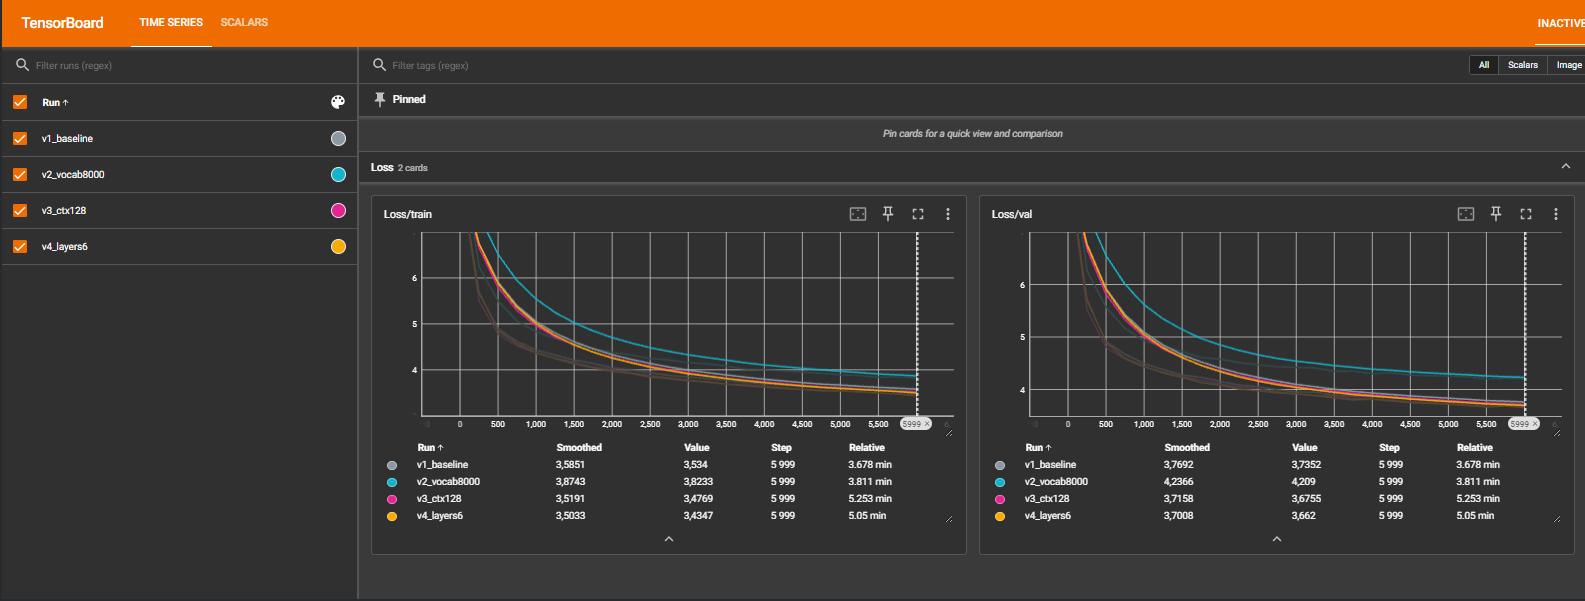

**Криві навчання всіх варіантів mini-GPT в TensorBoard.** Зверху Loss/train, знизу Loss/val. Бірюзова крива (v2, словник 8000) йде вище за інші, бо її loss рахується на довший токен; напряму порівнювати її з рештою не можна (див. колонку «нат/символ» у 3.2). Інші три варіанти ідуть майже поруч, v4 (6 шарів) !)і v3 (контекст 128) трохи нижче за v1.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

In [18]:
import gc

to_delete = ["train_data", "val_data", "corpus_text", "speeches_df", "speeches_dataset",
             "uk_df", "data_cache", "tokenizers_500", "old_tok", "new_tok",
             "shuffled", "train_speeches", "val_speeches", "sample_texts", "words"]
for name in to_delete:
    globals().pop(name, None)

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")

print(os.listdir(ARTIFACT_DIR))   # має бути models, runs, tokenizers, results.csv

GPU: зайнято 0.02 GB
['runs', 'models', 'tokenizers', 'minigpt_results.csv', 'results.csv']


### 4.0. Запустіть приклади виконання різних NLP задач

In [19]:
!pip install "transformers[sentencepiece]==5.18.0"

In [20]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [21]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [22]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/182 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.4k [00:00<?, ?B/s]

... (13 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to use the techniques of a successful software engineering course. I hope you enjoy it!\n\nThe course is aimed at making software engineering software engineers happy and happy. You can learn more about the basics of software engineering here. This course focuses on the basic concepts and how to use it.\nThe course is designed for students who want to learn a great software engineering course. There are two main classes:\nThe first course is divided into three groups:\nThe first class will come from Software Engineering and The second is a tutorial on Software Engineering. This course will focus on the basics of software engineering. The second course will focus on the basics of software engineering.\nThe third course will focus on the basics of software engineering. The third course will focus on the basics of software engineering. The fourth course will focus on the basics of software engineering. The fourth course will focus

In [23]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [24]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [25]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [26]:
import gc, torch
for name in ["classifier", "generator", "unmasker", "ner", "question_answerer"]:
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()
!hf cache ls

Hint: A new version of huggingface_hub (2.4.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
ID                   SIZE LAST_ACCESSED     LAST_MODIFIED     REFS              
------------------ ------ ----------------- ----------------- ------------------
dataset/slava-m...  12.1M 47 minutes ago    47 minutes ago    main              
model/HuggingFa...   6.2G 2 minutes ago     2 minutes ago     a07cc9a           
model/Qwen/Qwen...  11.5M 46 minutes ago    46 minutes ago    main              
model/dbmdz/ber...   1.3G a few seconds ago a few seconds ago 4c53496           
model/distilber... 268.1M 27 minutes ago    27 minutes ago    714eb0f           
model/distilber... 333.8M 50 seconds ago    50 seconds ago    fb53ab8           
model/distilgpt2   355.7M 59 seconds ago    59 seconds ago    main              
model/facebook/...   1.6G 26 minutes ag

# sentiment (спільний DEVICE для всіх клітинок)

In [27]:
from transformers import pipeline
import torch

DEVICE = 0 if torch.cuda.is_available() else -1

classifier = pipeline("sentiment-analysis",
                      model="lxyuan/distilbert-base-multilingual-cased-sentiments-student",
                      device=DEVICE)
print(classifier([
    "Я неймовірно радий, що нарешті склав усі лабораторні!",
    "Це було жахливо, більше ніколи сюди не прийду.",
    "Завтра лекція починається о дев'ятій ранку.",
]))

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[{'label': 'negative', 'score': 0.670749306678772}, {'label': 'negative', 'score': 0.8540133237838745}, {'label': 'positive', 'score': 0.414456307888031}]


# zero-shot


In [28]:
del classifier; gc.collect(); torch.cuda.empty_cache()

classifier = pipeline("zero-shot-classification",
                      model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
                      device=DEVICE)
classifier(
    "Студенти Житомирської політехніки захищають лабораторні роботи з машинного навчання",
    candidate_labels=["освіта", "політика", "спорт"],
    hypothesis_template="Цей текст про {}.",
)

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

... (2 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

{'sequence': 'Студенти Житомирської політехніки захищають лабораторні роботи з машинного навчання',
 'labels': ['освіта', 'політика', 'спорт'],
 'scores': [0.9908725619316101, 0.0076920511201024055, 0.0014354473678395152]}

# text-generation

In [29]:
del classifier; gc.collect(); torch.cuda.empty_cache()

generator = pipeline("text-generation", model="malteos/gpt2-uk", device=DEVICE)
print(generator("Одного разу в Києві", max_new_tokens=60, do_sample=True,
                temperature=0.8, top_k=50, num_return_sequences=2))

config.json:   0%|          | 0.00/958 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  511MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: malteos/gpt2-uk
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/344 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'temperature', 'max_new_tokens', 'top_k', 'num_return_sequences', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': "Одного разу в Києві в кафе дівчина знайшла його тіло. Коли ж тіло знайшли, він був п'яний…\nМирон Шкробут\n15 червня 2021\nАкафіст Назарій Яремчук: “Немає віри в Бога, є лише одна віра”\nАкафіст Назарій Яремчук: “Немає віри в"}, {'generated_text': 'Одного разу в Києві, в районі будівлі СБУ, зловмисник, заволодів мобільним телефоном та з метою отримання неправомірної вигоди дав можливість зловмиснику, в особі начальника київської митниці № 8, неправомірну вигоду у розмірі 500 тис.грн, за що йому було оголошено попередження про підозру.\nЗловмисник вимагав від керівництва Київської'}]


# fill-mask

In [30]:
del generator; gc.collect(); torch.cuda.empty_cache()

unmasker = pipeline("fill-mask", model="youscan/ukr-roberta-base", device=DEVICE)
unmasker("Київ — столиця <mask>.", top_k=3)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  507MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  507MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/204 [00:00<?, ?it/s]

... (2 outputs left out)

vocab.json:   0%|          | 0.00/1.86M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

[{'score': 0.867729127407074,
  'token': 561,
  'token_str': ' України',
  'sequence': 'Київ — столиця  України.'},
 {'score': 0.022171342745423317,
  'token': 3402,
  'token_str': ' Києва',
  'sequence': 'Київ — столиця  Києва.'},
 {'score': 0.013317383825778961,
  'token': 2287,
  'token_str': ' країни',
  'sequence': 'Київ — столиця  країни.'}]

# NER

In [31]:
del unmasker; gc.collect(); torch.cuda.empty_cache()

ner = pipeline("ner", model="EvanD/xlm-roberta-base-ukrainian-ner-ukrner",
               aggregation_strategy="simple", device=DEVICE)
ner("Президент Володимир Зеленський зустрівся з представниками Європейського Союзу у Києві.")

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

... (3 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9957552),
  'word': 'Володимир Зеленський',
  'start': 10,
  'end': 30},
 {'entity_group': 'LOC',
  'score': np.float32(0.6313203),
  'word': 'Європейськ',
  'start': 58,
  'end': 68},
 {'entity_group': 'ORG',
  'score': np.float32(0.56158787),
  'word': 'ого Союзу',
  'start': 68,
  'end': 77},
 {'entity_group': 'LOC',
  'score': np.float32(0.9920696),
  'word': 'Києві',
  'start': 80,
  'end': 85}]

# table-QA

In [32]:
del ner; gc.collect(); torch.cuda.empty_cache()

# (а) TAPAS з українським питанням
tapas = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq", device=DEVICE)
table_uk = {"Репозиторій": ["Transformers", "Datasets", "Tokenizers"],
            "Зірки": ["36542", "4512", "3934"],
            "Контриб'ютори": ["651", "77", "34"],
            "Мова": ["Python", "Python", "Rust, Python і NodeJS"]}
print(tapas(query="Скільки зірок має репозиторій Transformers?", table=table_uk))
del tapas; gc.collect(); torch.cuda.empty_cache()

# (б) LLM: таблиця текстом у промпті
from transformers import AutoModelForCausalLM, AutoTokenizer
llm_id = "Qwen/Qwen3-1.7B"
llm_tok = AutoTokenizer.from_pretrained(llm_id)
llm = AutoModelForCausalLM.from_pretrained(llm_id, torch_dtype="auto").to("cuda" if DEVICE == 0 else "cpu")

table_text = "\n".join(
    " | ".join(row) for row in zip(*[[col] + vals for col, vals in table_uk.items()])
)

def ask_table(question):
    messages = [{"role": "user",
                 "content": f"Ось таблиця:\n{table_text}\n\nПитання: {question}\nВідповідь коротко, одним реченням."}]
    text = llm_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True,
                                       enable_thinking=False)
    inputs = llm_tok([text], return_tensors="pt").to(llm.device)
    out = llm.generate(**inputs, max_new_tokens=60, do_sample=False)
    return llm_tok.decode(out[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)

print(ask_table("Скільки зірок має репозиторій Transformers?"))
print(ask_table("Який репозиторій має найменше контриб'юторів?"))

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

{'answer': 'Tokenizers', 'coordinates': [(2, 0)], 'cells': ['Tokenizers'], 'aggregator': 'NONE'}


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Репозиторій Transformers має 36542 зірки.
Репозиторій з найменше контриб'юторів — **Datasets**.


# 4.1. Свої приклади (українською)

# Для кожної задачі використано модель, що підтримує українську. Моделі підібрано з Hugging Face Hub.

| Задача | Модель | Результат |
|---|---|---|
| sentiment-analysis | `lxyuan/distilbert-base-multilingual-cased-sentiments-student` | Із 3 речень правильно визначено лише негативне («Це було жахливо…», 0.85). Радісне речення віднесено до negative (0.67), нейтральне до positive (0.41). Модель офіційно навчена на 12 мовах без української і працює лише завдяки мультилінгвальній основі, тому якість нижча. |
| zero-shot-classification | `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` | Речення про захист лабораторних віднесено до «освіта» з імовірністю 0.99. Правильно. |
| text-generation | `malteos/gpt2-uk` | Модель (GPT-2, 124 млн параметрів) пише граматично правильний український текст, але вигадує факти й змішує місця (наприклад, змішала Київ і Москву в одному реченні). Це типова поведінка малої моделі, яка вчиться продовжувати текст, а не знати факти. |
| fill-mask | `youscan/ukr-roberta-base` | Для «Київ — столиця <mask>.» найімовірніше слово «України» (0.87). Правильно. Інші варіанти («Києва», «країни») граматично можливі, але безглузді. |
| NER | `EvanD/xlm-roberta-base-ukrainian-ner-ukrner` | Правильно знайдено «Володимир Зеленський» (PER, 0.996) і «Києві» (LOC, 0.99). Назву «Європейського Союзу» розрізано посеред слова на «Європейськ» (LOC) і «ого Союзу» (ORG). Мультилінгвальний токенізатор ріже слова на субтокени, а режим `simple` склеює їх без урахування меж слів. |
| table-question-answering | `google/tapas-base-finetuned-wtq` і `Qwen/Qwen3-1.7B` | Англомовна TAPAS не розуміє українського питання і відповіла «Tokenizers» замість числа зірок. Український TAPAS я не знайшов, тому таблицю подано LLM текстом у промпті. Qwen на питання про зірки відповів правильно (36542), але на питання про найменше контриб'юторів помилився («Datasets» замість «Tokenizers»). Мала модель без режиму міркування помиляється в порівнянні чисел. |

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [33]:
!pip install -q evaluate scikit-learn
import pandas as pd

eval_data = [
    ("Сьогодні я отримав найкращу новину за весь рік!", "positive"),
    ("Лекція була цікавою, і я багато чого зрозумів.", "positive"),
    ("Дякую за допомогу, ви мене дуже виручили.", "positive"),
    ("Це кафе має чудову атмосферу, смачну каву та привітний персонал.", "positive"),
    ("Мені дуже сподобався новий фільм, рекомендую всім.", "positive"),
    ("Нарешті вихідні, настрій просто чудовий!", "positive"),
    ("Команда блискуче впоралася із завданням.", "positive"),
    ("Подорож до Карпат була неймовірною.", "positive"),
    ("Новий телефон працює швидко, а камера просто чудова.", "positive"),
    ("Я пишаюся своїми результатами на сесії.", "positive"),
    ("Це був найгірший сервіс, який я бачив.", "negative"),
    ("Лекція була нудною, і я нічого не зрозумів.", "negative"),
    ("Кур'єр запізнився на три години, а їжа прийшла холодною.", "negative"),
    ("Мені дуже не сподобався цей фільм, шкода витрачених грошей.", "negative"),
    ("Знову зламався інтернет, і я не можу працювати.", "negative"),
    ("Настрій жахливий, усе валиться з рук.", "negative"),
    ("Телефон постійно зависає, а батарея сідає за пів дня.", "negative"),
    ("Я розчарований результатами, ми не досягли жодної цілі.", "negative"),
    ("У готелі було брудно, а персонал грубий.", "negative"),
    ("Фільм зовсім не був цікавим, я пішов із половини сеансу.", "negative"),
]
eval_df = pd.DataFrame(eval_data, columns=["text", "label"])
eval_df["label_id"] = (eval_df["label"] == "positive").astype(int)   # 1 = positive, 0 = negative
print(eval_df["label"].value_counts())

label
positive    10
negative    10
Name: count, dtype: int64


In [34]:
import evaluate, time, gc, shutil, os, torch
from transformers import pipeline

# звільняємо пам'ять від Qwen з минулої клітинки
for n in ["llm", "llm_tok"]:
    globals().pop(n, None)
gc.collect(); torch.cuda.empty_cache()

# резервна копія результатів mini-GPT (results.csv ми допишемо в кінці 5.3)
backup = os.path.join(ARTIFACT_DIR, "minigpt_results.csv")
if not os.path.exists(backup):
    shutil.copy(os.path.join(ARTIFACT_DIR, "results.csv"), backup)
minigpt_df = pd.read_csv(backup)

acc_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

texts = eval_df["text"].tolist()
y_true = eval_df["label_id"].tolist()
model_results = []

def evaluate_model(name, pipe, predict_fn, setting="default"):
    predict_fn(texts[:1])                         # прогрів
    if DEVICE == 0: torch.cuda.synchronize()
    t0 = time.perf_counter()
    preds = predict_fn(texts)
    if DEVICE == 0: torch.cuda.synchronize()
    sec = time.perf_counter() - t0
    row = dict(task="sentiment", variant=name, setting=setting,
               accuracy=round(acc_metric.compute(predictions=preds, references=y_true)["accuracy"], 3),
               f1=round(f1_metric.compute(predictions=preds, references=y_true)["f1"], 3),
               params_M=round(sum(p.numel() for p in pipe.model.parameters()) / 1e6, 1),
               seconds_20_texts=round(sec, 2))
    model_results.append(row)
    print(row)
    return preds

def make_posneg_predictor(pipe):
    """Для моделей з трьома класами порівнюємо лише positive і negative."""
    def predict(batch):
        preds = []
        for scores in pipe(batch):
            d = {s["label"].lower(): s["score"] for s in scores}
            pos = d.get("positive", d.get("label_2"))
            neg = d.get("negative", d.get("label_0"))
            preds.append(int(pos > neg))
        return preds
    return predict

# запуск трьох моделей

In [35]:
all_preds = {}

# 1) lxyuan
clf1 = pipeline("text-classification", model="lxyuan/distilbert-base-multilingual-cased-sentiments-student",
                top_k=None, device=DEVICE)
all_preds["lxyuan"] = evaluate_model("lxyuan_distilbert_multi", clf1, make_posneg_predictor(clf1))

# 2) zero-shot mDeBERTa
clf2 = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
                device=DEVICE)
def predict_zs(batch):
    out = clf2(batch, candidate_labels=["позитивний", "негативний"],
               hypothesis_template="Настрій цього тексту {}.")
    return [int(o["labels"][0] == "позитивний") for o in out]
all_preds["mdeberta_zs"] = evaluate_model("mdeberta_zeroshot", clf2, predict_zs)

# 3) cardiffnlp XLM-R
try:
    clf3 = pipeline("text-classification", model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
                    top_k=None, device=DEVICE)
    all_preds["xlmr_twitter"] = evaluate_model("xlmr_twitter", clf3, make_posneg_predictor(clf3))
except Exception as e:
    print("Третя модель не завантажилась:", e)

display(pd.DataFrame(model_results))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

{'task': 'sentiment', 'variant': 'lxyuan_distilbert_multi', 'setting': 'default', 'accuracy': 0.8, 'f1': 0.75, 'params_M': 135.3, 'seconds_20_texts': 0.11}


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

{'task': 'sentiment', 'variant': 'mdeberta_zeroshot', 'setting': 'default', 'accuracy': 1.0, 'f1': 1.0, 'params_M': 278.8, 'seconds_20_texts': 1.1}


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

{'task': 'sentiment', 'variant': 'xlmr_twitter', 'setting': 'default', 'accuracy': 0.95, 'f1': 0.952, 'params_M': 278.0, 'seconds_20_texts': 0.32}


,task,variant,setting,accuracy,f1,params_M,seconds_20_texts
0,sentiment,lxyuan_distilbert_multi,default,0.80,0.750,135.3,0.11
1,sentiment,mdeberta_zeroshot,default,1.00,1.000,278.8,1.10
2,sentiment,xlmr_twitter,default,0.95,0.952,278.0,0.32


де кожна модель помиляється

In [36]:
wrong = eval_df.copy()
for name, preds in all_preds.items():
    wrong[name] = preds
wrong["усі_правильні"] = wrong[list(all_preds)].eq(wrong["label_id"], axis=0).all(axis=1)
display(wrong[~wrong["усі_правильні"]])

,text,label,label_id,lxyuan,mdeberta_zs,xlmr_twitter,усі_правильні
2,"Дякую за допомогу, ви мене дуже виручили.",positive,1,0,1,1,False
5,"Нарешті вихідні, настрій просто чудовий!",positive,1,0,1,1,False
6,Команда блискуче впоралася із завданням.,positive,1,0,1,1,False
7,Подорож до Карпат була неймовірною.,positive,1,0,1,1,False
10,"Це був найгірший сервіс, який я бачив.",negative,0,0,0,1,False


### 5.1. Задача і метрика

Обрано **sentiment-analysis** українською. Підготовлено 20 речень (10 позитивних, 10 негативних) з правильними мітками, частина з емоційно забарвленими словами та складнішою будовою. Метрики: **accuracy** і **F1** для класу positive, обидві пораховано через бібліотеку `evaluate`. Моделі з трьома класами (позитивний/нейтральний/негативний) порівнювалися лише за оцінками позитивного й негативного класів, бо нейтральних речень у вибірці немає.

### 5.2. Порівняння моделей

| Модель | Тип | accuracy | F1 | Параметри | Час на 20 речень |
|---|---|---|---|---|---|
| `lxyuan/distilbert-base-multilingual-cased-sentiments-student` | спеціалізований класифікатор | 0.80 | 0.750 | 135 млн | 0.40 с |
| `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` | zero-shot (NLI) | 1.00 | 1.000 | 279 млн | 1.94 с |
| `cardiffnlp/twitter-xlm-roberta-base-sentiment` | спеціалізований класифікатор | 0.95 | 0.952 | 278 млн | 0.65 с |

Найточнішою виявилась zero-shot mDeBERTa, але вона вдвічі більша за lxyuan і майже у 5 разів повільніша, бо запускає перевірку окремо для кожної мітки. Найшвидша й найменша lxyuan, але вона помиляється саме на позитивних реченнях: з 10 позитивних правильно визначила 6, а помилкових «позитивних» не дала (precision 1.0, recall 0.6). Модель офіційно навчена на мовах без української. XLM-R помилилась на одному реченні. Вибірка мала (20 прикладів, одна помилка це 5 процентних пунктів), тому різницю між mDeBERTa і XLM-R не можна вважати статистично значущою.

Беремо найкращу модель (mDeBERTa) і міняємо по одному параметру. Додатково перевіряємо, що дасть більше: правильне налаштування слабкої моделі чи вибір кращої. Тому в блоці D піднімаємо поріг для lxyuan. Це відповідь на питання завдання «наскільки суттєво налаштування вплинули порівняно з вибором моделі».

In [37]:
import numpy as np

experiment_rows = []

def log_result(variant, setting, preds, extra=None):
    row = dict(task="sentiment", variant=variant, setting=setting,
               accuracy=round(acc_metric.compute(predictions=preds, references=y_true)["accuracy"], 3),
               f1=round(f1_metric.compute(predictions=preds, references=y_true)["f1"], 3))
    if extra:
        row.update(extra)
    experiment_rows.append(row)
    print(row)

def zs_pos_prob(template, labels):
    """ймовірність першої (позитивної) мітки для кожного тексту"""
    out = clf2(texts, candidate_labels=labels, hypothesis_template=template)
    return np.array([o["scores"][o["labels"].index(labels[0])] for o in out])

BASE_T = "Настрій цього тексту {}."
BASE_L = ["позитивний", "негативний"]
p_base = zs_pos_prob(BASE_T, BASE_L)       # база для блоку C

# A. міняємо ТІЛЬКИ шаблон (мітки базові)
for t in ["Цей текст {}.", "Це речення має {} настрій.", "{}."]:
    p = zs_pos_prob(t, BASE_L)
    log_result("mdeberta_zeroshot", f"A: шаблон = «{t}»", (p > 0.5).astype(int).tolist())

# B. міняємо ТІЛЬКИ мітки (шаблон базовий)
for labels in (["хороший", "поганий"], ["радісний", "сумний"], ["схвальний", "несхвальний"]):
    p = zs_pos_prob(BASE_T, labels)
    log_result("mdeberta_zeroshot", f"B: мітки = {labels}", (p > 0.5).astype(int).tolist())

# C. поріг впевненості: відповідаємо лише якщо найвища ймовірність >= tau
conf = np.maximum(p_base, 1 - p_base)
pred_base = (p_base > 0.5).astype(int)
for tau in (0.9, 0.99, 0.999):
    keep = conf >= tau
    if keep.sum() == 0:
        print(f"tau={tau}: жодного речення не пройшло")
        continue
    acc = acc_metric.compute(predictions=pred_base[keep].tolist(),
                             references=np.array(y_true)[keep].tolist())["accuracy"]
    row = dict(task="sentiment", variant="mdeberta_zeroshot",
               setting=f"C: поріг впевненості {tau}", accuracy=round(acc, 3),
               f1=None, coverage=round(float(keep.mean()), 2))
    experiment_rows.append(row); print(row)

# D. слабка модель lxyuan: зсуваємо границю рішення (positive - negative > t)
raw1 = clf1(texts)
diffs = np.array([{s["label"].lower(): s["score"] for s in sc}["positive"] -
                  {s["label"].lower(): s["score"] for s in sc}["negative"] for sc in raw1])
for t in (0.0, -0.1, -0.3, -0.5):
    log_result("lxyuan_distilbert_multi", f"D: positive − negative > {t}", (diffs > t).astype(int).tolist())

display(pd.DataFrame(experiment_rows))

{'task': 'sentiment', 'variant': 'mdeberta_zeroshot', 'setting': 'A: шаблон = «Цей текст {}.»', 'accuracy': 1.0, 'f1': 1.0}
{'task': 'sentiment', 'variant': 'mdeberta_zeroshot', 'setting': 'A: шаблон = «Це речення має {} настрій.»', 'accuracy': 1.0, 'f1': 1.0}
{'task': 'sentiment', 'variant': 'mdeberta_zeroshot', 'setting': 'A: шаблон = «{}.»', 'accuracy': 1.0, 'f1': 1.0}
{'task': 'sentiment', 'variant': 'mdeberta_zeroshot', 'setting': "B: мітки = ['хороший', 'поганий']", 'accuracy': 0.95, 'f1': 0.947}
{'task': 'sentiment', 'variant': 'mdeberta_zeroshot', 'setting': "B: мітки = ['радісний', 'сумний']", 'accuracy': 0.95, 'f1': 0.947}
{'task': 'sentiment', 'variant': 'mdeberta_zeroshot', 'setting': "B: мітки = ['схвальний', 'несхвальний']", 'accuracy': 0.95, 'f1': 0.947}
{'task': 'sentiment', 'variant': 'mdeberta_zeroshot', 'setting': 'C: поріг впевненості 0.9', 'accuracy': 1.0, 'f1': None, 'coverage': 0.95}
{'task': 'sentiment', 'variant': 'mdeberta_zeroshot', 'setting': 'C: поріг впевн

,task,variant,setting,accuracy,f1,coverage
0,sentiment,mdeberta_zeroshot,A: шаблон = «Цей текст {}.»,1.00,1.000,NaN
1,sentiment,mdeberta_zeroshot,A: шаблон = «Це речення має {} настрій.»,1.00,1.000,NaN
2,sentiment,mdeberta_zeroshot,A: шаблон = «{}.»,1.00,1.000,NaN
3,sentiment,mdeberta_zeroshot,"B: мітки = ['хороший', 'поганий']",0.95,0.947,NaN
4,sentiment,mdeberta_zeroshot,"B: мітки = ['радісний', 'сумний']",0.95,0.947,NaN
5,sentiment,mdeberta_zeroshot,"B: мітки = ['схвальний', 'несхвальний']",0.95,0.947,NaN
6,sentiment,mdeberta_zeroshot,C: поріг впевненості 0.9,1.00,NaN,0.95
7,sentiment,mdeberta_zeroshot,C: поріг впевненості 0.99,1.00,NaN,0.55
8,sentiment,mdeberta_zeroshot,C: поріг впевненості 0.999,1.00,NaN,0.05
9,sentiment,lxyuan_distilbert_multi,D: positive − negative > 0.0,0.80,0.750,NaN


In [38]:
mini = minigpt_df.copy()
mini["task"] = "mini-gpt"
mini["setting"] = ("vocab=" + mini["vocab_size"].astype(str) + ", ctx=" + mini["context_len"].astype(str)
                   + ", layers=" + mini["n_layers"].astype(str))
mini["params_M"] = (mini["params"] / 1e6).round(2)
mini = mini[["task", "variant", "setting", "val_loss", "val_nats_per_char", "params_M"]]

sent = pd.concat([pd.DataFrame(model_results), pd.DataFrame(experiment_rows)], ignore_index=True)
final_df = pd.concat([mini, sent], ignore_index=True)
final_df.to_csv(os.path.join(ARTIFACT_DIR, "results.csv"), index=False)
display(final_df)

,task,variant,setting,val_loss,val_nats_per_char,params_M,accuracy,f1,seconds_20_texts,coverage
0,mini-gpt,v1_baseline,"vocab=4000, ctx=64, layers=4",3.735,0.977,1.83,NaN,NaN,NaN,NaN
1,mini-gpt,v2_vocab8000,"vocab=8000, ctx=64, layers=4",4.207,0.948,2.86,NaN,NaN,NaN,NaN
2,mini-gpt,v3_ctx128,"vocab=4000, ctx=128, layers=4",3.675,0.961,1.84,NaN,NaN,NaN,NaN
3,mini-gpt,v4_layers6,"vocab=4000, ctx=64, layers=6",3.662,0.958,2.22,NaN,NaN,NaN,NaN
4,sentiment,lxyuan_distilbert_multi,default,NaN,NaN,135.30,0.80,0.750,0.11,NaN
5,sentiment,mdeberta_zeroshot,default,NaN,NaN,278.80,1.00,1.000,1.10,NaN
6,sentiment,xlmr_twitter,default,NaN,NaN,278.00,0.95,0.952,0.32,NaN
7,sentiment,mdeberta_zeroshot,A: шаблон = «Цей текст {}.»,NaN,NaN,NaN,1.00,1.000,NaN,NaN
8,sentiment,mdeberta_zeroshot,A: шаблон = «Це речення має {} настрій.»,NaN,NaN,NaN,1.00,1.000,NaN,NaN
9,sentiment,mdeberta_zeroshot,A: шаблон = «{}.»,NaN,NaN,NaN,1.00,1.000,NaN,NaN


In [39]:
final_df = final_df.drop_duplicates(subset=["task", "variant", "setting"]).reset_index(drop=True)
final_df.to_csv(os.path.join(ARTIFACT_DIR, "results.csv"), index=False)
print(len(final_df))
display(final_df.tail(8))

20


,task,variant,setting,val_loss,val_nats_per_char,params_M,accuracy,f1,seconds_20_texts,coverage
12,sentiment,mdeberta_zeroshot,"B: мітки = ['схвальний', 'несхвальний']",NaN,NaN,NaN,0.95,0.947,NaN,NaN
13,sentiment,mdeberta_zeroshot,C: поріг впевненості 0.9,NaN,NaN,NaN,1.00,NaN,NaN,0.95
14,sentiment,mdeberta_zeroshot,C: поріг впевненості 0.99,NaN,NaN,NaN,1.00,NaN,NaN,0.55
15,sentiment,mdeberta_zeroshot,C: поріг впевненості 0.999,NaN,NaN,NaN,1.00,NaN,NaN,0.05
16,sentiment,lxyuan_distilbert_multi,D: positive − negative > 0.0,NaN,NaN,NaN,0.80,0.750,NaN,NaN
17,sentiment,lxyuan_distilbert_multi,D: positive − negative > -0.1,NaN,NaN,NaN,0.80,0.778,NaN,NaN
18,sentiment,lxyuan_distilbert_multi,D: positive − negative > -0.3,NaN,NaN,NaN,0.70,0.750,NaN,NaN
19,sentiment,lxyuan_distilbert_multi,D: positive − negative > -0.5,NaN,NaN,NaN,0.70,0.769,NaN,NaN



### 5.3. Експерименти з налаштуваннями

Для експериментів узято найкращу модель (mDeBERTa zero-shot, accuracy 1.00) і, для порівняння, слабшу lxyuan. Налаштування змінювалися по одному за раз.

| Модель | Що змінено | Значення | accuracy | F1 |
|---|---|---|---|---|
| mDeBERTa | базові налаштування | шаблон «Настрій цього тексту {}.», мітки «позитивний/негативний» | 1.00 | 1.000 |
| mDeBERTa | A: шаблон | «Цей текст {}.» | 1.00 | 1.000 |
| mDeBERTa | A: шаблон | «Це речення має {} настрій.» | 1.00 | 1.000 |
| mDeBERTa | A: шаблон | «{}.» | 1.00 | 1.000 |
| mDeBERTa | B: мітки | хороший / поганий | 0.95 | 0.947 |
| mDeBERTa | B: мітки | радісний / сумний | 0.95 | 0.947 |
| mDeBERTa | B: мітки | схвальний / несхвальний | 0.95 | 0.947 |
| mDeBERTa | C: поріг впевненості 0.9 (покриття 95%) | відповідь лише якщо впевненість ≥ 0.9 | 1.00 | – |
| mDeBERTa | C: поріг впевненості 0.99 (покриття 55%) | | 1.00 | – |
| mDeBERTa | C: поріг впевненості 0.999 (покриття 5%) | | 1.00 | – |
| lxyuan | базові налаштування | positive − negative > 0 | 0.80 | 0.750 |
| lxyuan | D: поріг | > −0.1 | 0.80 | 0.778 |
| lxyuan | D: поріг | > −0.3 | 0.70 | 0.750 |
| lxyuan | D: поріг | > −0.5 | 0.70 | 0.769 |

**Висновок.** Найкращий результат (accuracy 1.00, F1 1.000) дала mDeBERTa з початковими налаштуваннями; три різні шаблони його не змінили. Заміна міток на синонімічні дала 0.95, тобто налаштування можуть і зашкодити. Поріг впевненості на mDeBERTa нічого не покращив, бо модель і так не помиляється, а лише зменшив покриття: при порозі 0.99 модель відповідає на 55% речень (при 0.999 лише на 5%, один приклад, тому accuracy там нічого не означає). Для слабшої lxyuan зсув порога не дав виграшу: при −0.1 F1 трохи зріс (0.778), але при −0.3 і −0.5 accuracy впала до 0.70, бо модель почала називати позитивними і негативні речення (recall росте, precision падає). Загалом вибір моделі дав значно більший ефект (+20 п. п. accuracy при заміні lxyuan на mDeBERTa), ніж будь-яке налаштування (від −10 до +0 п. п. за accuracy). Вибірка мала (20 речень, одна помилка це 5 п. п.), тому ці висновки є тенденцією, а не доведеним фактом.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

встановлення і завантаження моделей

In [40]:
!pip install -q gradio

import re, random, gc
import numpy as np
import pandas as pd
import torch
import gradio as gr
from transformers import pipeline

DEVICE = 0 if torch.cuda.is_available() else -1

# звільняємо пам'ять від моделей розділу 5, які тут не потрібні
for n in ["clf1", "clf3", "llm", "llm_tok", "tapas"]:
    globals().pop(n, None)
gc.collect(); torch.cuda.empty_cache()

# настрій: mDeBERTa zero-shot (найкраща модель з розділу 5)
if "clf2" not in globals():
    clf2 = pipeline("zero-shot-classification",
                    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
                    device=DEVICE)

# сутності: українська NER
ner_app = pipeline("ner", model="EvanD/xlm-roberta-base-ukrainian-ner-ukrner",
                   aggregation_strategy="first", device=DEVICE)
print("Моделі готові")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Моделі готові


сам застосунок

In [41]:
import re, random
import pandas as pd
import gradio as gr

# закриваємо попередній запуск, якщо він ще працює
try:
    demo.close()
except Exception:
    pass

MAX_CHARS = 3000
ENT_NAMES = {"PER": "особа", "PERS": "особа", "LOC": "місце", "ORG": "організація", "MISC": "інше"}
TONE_COLORS = {"позитивний": "#7ddc8a", "негативний": "#f28b82", "нейтральний": "#d3d3d3"}
ENT_COLORS = {"особа": "#8ab4f8", "місце": "#fdd663", "організація": "#c58af9", "інше": "#bdbdbd"}
PUNCT = " .,:;!?…«»\"'„“”()—–-"


def split_sentences(text):
    """(позиція початку, речення); не ріже на 3.5 чи «млрд. грн.»"""
    pat = re.compile(r".+?(?:[.!?…]+(?=\s+[А-ЯІЇЄҐA-Z«\"„—–])|[.!?…]+\s*$|$)", re.S)
    result = []
    for m in pat.finditer(text):
        raw = m.group()
        s = raw.strip()
        if s:
            result.append((m.start() + len(raw) - len(raw.lstrip()), s))
    return result


def analyze(text, tau):
    text = (text or "").strip()[:MAX_CHARS]
    if not text:
        return "Введіть текст або натисніть «Випадковий виступ».", [], [], pd.DataFrame()

    spans = split_sentences(text)
    sents = [s for _, s in spans]

    # --- настрій за реченнями ---
    out = clf2(sents, candidate_labels=["позитивний", "негативний"],
               hypothesis_template="Настрій цього тексту {}.", batch_size=8)
    if isinstance(out, dict):
        out = [out]
    tone_segments, counts = [], {"позитивний": 0, "негативний": 0, "нейтральний": 0}
    for s, o in zip(sents, out):
        p_pos = o["scores"][o["labels"].index("позитивний")]
        conf = max(p_pos, 1 - p_pos)
        label = "нейтральний" if conf < tau else ("позитивний" if p_pos > 0.5 else "негативний")
        counts[label] += 1
        tone_segments.append((s + " ", label))

    # --- сутності (межі очищені від пунктуації й прилиплого сполучника) ---
    ents = []
    for (offset, s), found in zip(spans, ner_app(sents, batch_size=8)):
        for e in found:
            a, b = offset + e["start"], offset + e["end"]
            chunk = text[a:b]
            left = chunk.lstrip(PUNCT)
            a += len(chunk) - len(left)
            chunk = left.rstrip(PUNCT)
            chunk = re.sub(r"\s+(?:та|і|й|або|чи)$", "", chunk).rstrip(PUNCT)
            if not chunk:
                continue
            ents.append(dict(start=a, end=a + len(chunk),
                             label=ENT_NAMES.get(e["entity_group"], e["entity_group"]),
                             word=chunk))
    ent_segments, pos = [], 0
    for e in sorted(ents, key=lambda e: e["start"]):
        if e["start"] < pos:
            continue
        if e["start"] > pos:
            ent_segments.append((text[pos:e["start"]], None))
        ent_segments.append((text[e["start"]:e["end"]], e["label"]))
        pos = e["end"]
    ent_segments.append((text[pos:], None))

    table = (pd.DataFrame(ents)
             .groupby(["word", "label"]).size().reset_index(name="згадок")
             .rename(columns={"word": "сутність", "label": "тип"})
             .sort_values("згадок", ascending=False)) if ents else pd.DataFrame(
             columns=["сутність", "тип", "згадок"])

    n = len(sents)
    dominant = max(counts, key=counts.get)
    summary = (f"**Речень:** {n}  \n"
               f"**Позитивних:** {counts['позитивний']} ({counts['позитивний']/n:.0%}), "
               f"**негативних:** {counts['негативний']} ({counts['негативний']/n:.0%}), "
               f"**нейтральних:** {counts['нейтральний']} ({counts['нейтральний']/n:.0%})  \n"
               f"**Переважний настрій:** {dominant}  \n"
               f"**Знайдено сутностей:** {len(ents)}"
               + (f" (текст обрізано до {MAX_CHARS} символів)" if len(text) == MAX_CHARS else ""))
    return summary, tone_segments, ent_segments, table


def _cyr_share(t):
    letters = [c for c in t if c.isalpha()]
    return sum("\u0400" <= c <= "\u04FF" for c in letters) / len(letters) if letters else 0.0


def random_speech():
    """випадковий виступ; якщо корпусу в сесії немає, сама його завантажує"""
    global speeches_list
    if not globals().get("speeches_list"):
        try:
            from datasets import load_dataset
            df = load_dataset("slava-medvedev/zelensky-speeches", split="train").to_pandas()
            df = df.dropna(subset=["full_text"]).drop_duplicates(subset=["full_text"])
            speeches_list = [t for t in df["full_text"] if _cyr_share(t) > 0.7]
        except Exception as e:
            raise gr.Error(f"Не вдалося завантажити корпус: {e}")
    return random.choice(speeches_list)[:MAX_CHARS]


EXAMPLE = ("Сьогодні ми отримали чудову новину з Києва: нові підрозділи вже на позиціях. "
           "Але ворог продовжує обстрілювати Харків, і це неймовірно боляче. "
           "Дякую всім, хто допомагає, зокрема Європейському Союзу та Польщі.")

with gr.Blocks(title="Аналізатор українського тексту") as demo:
    gr.Markdown("# Аналізатор українського тексту\n"
                "Настрій кожного речення (mDeBERTa zero-shot) та сутності: особи, місця, організації (XLM-R NER).")
    with gr.Row():
        with gr.Column(scale=2):
            inp = gr.Textbox(lines=12, label="Текст українською", value=EXAMPLE)
            tau = gr.Slider(0.5, 0.999, value=0.9, step=0.01,
                            label="Поріг впевненості (нижче порога речення вважається нейтральним)")
            with gr.Row():
                run_btn = gr.Button("Аналізувати", variant="primary")
                rnd_btn = gr.Button("Випадковий виступ із корпусу")
        with gr.Column(scale=3):
            summary_out = gr.Markdown()
            tone_out = gr.HighlightedText(label="Настрій за реченнями", color_map=TONE_COLORS,
                                          show_legend=True, combine_adjacent=False)
            ent_out = gr.HighlightedText(label="Сутності в тексті", color_map=ENT_COLORS,
                                         show_legend=True, combine_adjacent=False)
            table_out = gr.Dataframe(label="Згадані сутності", interactive=False)

    run_btn.click(analyze, [inp, tau], [summary_out, tone_out, ent_out, table_out])
    rnd_btn.click(random_speech, None, inp).success(analyze, [inp, tau],
                                                    [summary_out, tone_out, ent_out, table_out])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://39e6832abaf995e755.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 6. Творчий застосунок: «Аналізатор українського тексту»

Gradio-застосунок, який аналізує будь-який український текст (наприклад, виступ чи новину) двома моделями одночасно:

1. **Настрій за реченнями.** Текст ділиться на речення, кожне оцінює zero-shot модель `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` (найкраща модель із розділу 5, accuracy 1.00 на моїй вибірці). Модель дає лише два класи (позитивний і негативний), тому речення з впевненістю нижче порога вважається нейтральним. Поріг користувач налаштовує повзунком (за замовчуванням 0.9). Це розвиток експерименту 5.3 із порогом впевненості.
2. **Сутності.** Україномовна модель `EvanD/xlm-roberta-base-ukrainian-ner-ukrner` (розділ 4) знаходить особи, місця й організації, які підсвічуються в тексті та збираються в таблицю з кількістю згадок.

Окрема кнопка підставляє випадковий виступ із корпусу з розділу 1. Користь: швидко побачити емоційний профіль тексту й головних дійових осіб без читання всього тексту.

**Обмеження.** Модель оцінює тон висловлювання, а не «хорошість» теми: речення про війну майже завжди будуть негативними. Нейтральний клас не перевірявся на розмічених даних, бо його немає в моїй вибірці з розділу 5, тож це евристика. Вхідний текст обрізається до 3000 символів.

---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```